# Chapter 2 (Practical): Markov Baseline vs LSTM for Next-Event Prediction

**Aventum Round 1 prep · STRATEGY.md §7.2 (mini-build)** · Time needed: about 90 minutes

This is the **practical** for Chapter 1, like a lab journal: aim, apparatus, procedure, observations, result, conclusion.

| | |
|---|---|
| **Aim** | Predict the next event in a submission's lifecycle. Compare a first-order Markov chain, a second-order Markov chain and a small PyTorch LSTM on **accuracy@1** and **accuracy@3**, using a **time-based split**. |
| **Apparatus** | numpy, pandas, PyTorch (`nn.Embedding`, `nn.LSTM`, `Dataset`, `DataLoader`) |
| **Theory** | Chapter 1, §1.1 (Markov) and §1.3 (LSTM) |
| **Kernel** | `Python (aventum)`, the conda env `aventum`, which already has torch installed |

**Honest framing for Friday:** "I built this on synthetic data this week to compare a Markov baseline against an LSTM." It is not production experience.

## 0. Setup

In [1]:
# Libraries are installed in the conda env `aventum`. Do not pip install from inside the notebook.
import numpy as np                  # linear algebra
import pandas as pd                 # data processing
import matplotlib.pyplot as plt     # plots
from collections import Counter, defaultdict

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

np.random.seed(42)
torch.manual_seed(42)
print("torch", torch.__version__)

torch 2.14.1+cpu


---
## 1. Procedure step 1: generate a synthetic submission log

### Design of the simulator (so we know what "truth" looks like)
- Every submission is **Received → Triaged**.
- The underwriter may ask for more information: **InfoRequested → InfoReceived**, up to 3 times.
- 30% are **Referred** to a senior underwriter. Referred risks are declined more often and **re-quoted** more often.
- Otherwise **Quoted**, then possibly **Requoted**, then **Bound** or **NTU**.
- **History effect (deliberate):** P(Bound) rises with the number of info loops (an engaged broker) and falls if the risk was referred.

That history effect is the thing a first-order Markov chain **cannot** see: when the current state is *Quoted*, it doesn't know about the info loops or the referral earlier in the journey. An LSTM can, in principle. Let's find out if that matters in practice.

In [2]:
EVENTS = ["Received", "Triaged", "InfoRequested", "InfoReceived", "Referred",
          "Quoted", "Requoted", "Bound", "NTU", "Declined"]
PAD = 0
tok = {e: i + 1 for i, e in enumerate(EVENTS)}    # 0 is reserved for padding
itos = {i: e for e, i in tok.items()}
V = len(EVENTS) + 1                               # vocabulary size including PAD

def gen_journey(rng):
    path = ["Received", "Triaged"]
    while rng.random() < 0.35 and path.count("InfoRequested") < 3:
        path += ["InfoRequested", "InfoReceived"]
    referred = rng.random() < 0.30
    if referred:
        path.append("Referred")
    if rng.random() < (0.35 if referred else 0.10):
        return path + ["Declined"]
    path.append("Quoted")
    if rng.random() < (0.50 if referred else 0.15):
        path.append("Requoted")
    p_bind = 0.30 + 0.15 * path.count("InfoRequested") - 0.15 * referred
    return path + ["Bound" if rng.random() < p_bind else "NTU"]

rng = np.random.default_rng(42)
N = 8000
journeys = [gen_journey(rng) for _ in range(N)]
dates = pd.Timestamp("2024-01-01") + pd.to_timedelta(np.sort(rng.uniform(0, 640, N)), unit="D")

log = pd.DataFrame({"received_date": dates, "path": journeys})
log["length"] = log["path"].str.len()
log["path_str"] = log["path"].str.join(" > ")
print(log["length"].describe().round(2))
log.head()

count    8000.00
mean        5.33
std         1.78
min         3.00
25%         4.00
50%         5.00
75%         6.00
max        12.00
Name: length, dtype: float64


,received_date,path,length,path_str
0,2024-01-01 02:44:37.679306942,"[Received, Triaged, Quoted, Bound]",4,Received > Triaged > Quoted > Bound
1,2024-01-01 03:32:53.942396357,"[Received, Triaged, Quoted, Requoted, NTU]",5,Received > Triaged > Quoted > Requoted > NTU
2,2024-01-01 05:43:43.745924392,"[Received, Triaged, Quoted, NTU]",4,Received > Triaged > Quoted > NTU
3,2024-01-01 06:01:38.180896478,"[Received, Triaged, InfoRequested, InfoReceive...",7,Received > Triaged > InfoRequested > InfoRecei...
4,2024-01-01 07:32:52.027372199,"[Received, Triaged, Quoted, Bound]",4,Received > Triaged > Quoted > Bound


In [3]:
log["path_str"].value_counts().head(10)

path_str
Received > Triaged > Quoted > NTU                                                                    1950
Received > Triaged > Quoted > Bound                                                                   822
Received > Triaged > Referred > Declined                                                              583
Received > Triaged > InfoRequested > InfoReceived > Quoted > NTU                                      537
Received > Triaged > Referred > Quoted > NTU                                                          452
Received > Triaged > Referred > Quoted > Requoted > NTU                                               431
Received > Triaged > InfoRequested > InfoReceived > Quoted > Bound                                    427
Received > Triaged > Declined                                                                         360
Received > Triaged > Quoted > Requoted > NTU                                                          322
Received > Triaged > InfoRequested > 

## 2. Procedure step 2: time-based split
Train on the first 80% of submissions **by received date** and test on the last 20%. (Chapter 1 explained why a random split is wrong for event data.)

In [4]:
cut = int(N * 0.8)
train_j = log["path"].iloc[:cut].tolist()
test_j  = log["path"].iloc[cut:].tolist()
print("train:", log.received_date.iloc[0].date(), "->", log.received_date.iloc[cut - 1].date(), f"({len(train_j)} journeys)")
print("test :", log.received_date.iloc[cut].date(), "->", log.received_date.iloc[-1].date(), f"({len(test_j)} journeys)")

train: 2024-01-01 -> 2025-05-25 (6400 journeys)
test : 2025-05-25 -> 2025-10-01 (1600 journeys)


## 3. Procedure step 3: the evaluation set
For a journey $[e_1, e_2, \dots, e_n]$, there is one prediction at each step: given $e_1 \dots e_t$, predict $e_{t+1}$, for $t = 1 \dots n-1$.

### Solved Example 2.1 (how many test cases does one journey give?)
**Q.** Journey: Received → Triaged → Quoted → Bound. List the (history → target) pairs.

**Solution.** $n = 4$, so there are $n - 1 = 3$ pairs:
1. [Received] → Triaged
2. [Received, Triaged] → Quoted
3. [Received, Triaged, Quoted] → Bound

**Ans.** 3 prediction cases. A model that's 100% right on case 1 (always Triaged) inflates accuracy, so we'll also report accuracy on the **hard positions** where the history effect lives (current state = Quoted or Requoted).

In [5]:
def make_cases(journeys):
    cases = []                                    # (history list, target event)
    for j in journeys:
        for t in range(1, len(j)):
            cases.append((j[:t], j[t]))
    return cases

test_cases = make_cases(test_j)
print(len(test_cases), "test prediction cases")
print(test_cases[:3])

6946 test prediction cases
[(['Received'], 'Triaged'), (['Received', 'Triaged'], 'Quoted'), (['Received', 'Triaged', 'Quoted'], 'NTU')]


---
## 4. Model A: first-order Markov chain (the baseline)
Same formula as Chapter 1: $\hat p_{ij} = n_{ij} / \sum_k n_{ik}$. To predict, take the row for the **current** (last) event and rank the next events by probability.

In [6]:
class MarkovOrder1:
    def fit(self, journeys):
        self.counts = defaultdict(Counter)
        for j in journeys:
            for a, b in zip(j[:-1], j[1:]):
                self.counts[a][b] += 1
        return self

    def topk(self, history, k=3):
        row = self.counts[history[-1]]            # only the current state matters
        return [e for e, _ in row.most_common(k)]

m1 = MarkovOrder1().fit(train_j)
pd.DataFrame(m1.counts).T.fillna(0).astype(int).loc[EVENTS[:7]]

,Triaged,Quoted,InfoRequested,Referred,Declined,Bound,Requoted,NTU,InfoReceived
Received,6400,0,0,0,0,0,0,0,0
Triaged,0,2612,2217,1285,286,0,0,0,0
InfoRequested,0,0,0,0,0,0,0,0,3251
InfoReceived,0,1352,1034,689,176,0,0,0,0
Referred,0,1282,0,0,692,0,0,0,0
Quoted,0,0,0,0,0,1430,1185,2631,0
Requoted,0,0,0,0,0,376,0,809,0


#### Explanation
- `defaultdict(Counter)` is a dictionary of counters: `counts["Quoted"]["Bound"]` = $n_{Q,B}$.
- `most_common(k)` sorts the row by count, which is the same order as sorting by $\hat p_{ij}$, so we never need to divide.
- The table is the raw count matrix $n_{ij}$ (rows = current, columns = next).

## 5. Model B: second-order Markov chain
Condition on the **last two** events: $P(e_{t+1} \mid e_{t-1}, e_t)$. If a pair was never seen in training, **back off** to the first-order model. (Backoff is the practical alternative to Laplace smoothing.)

In [7]:
class MarkovOrder2:
    def fit(self, journeys):
        self.counts = defaultdict(Counter)
        for j in journeys:
            for a, b, c in zip(j[:-2], j[1:-1], j[2:]):
                self.counts[(a, b)][c] += 1
        self.backoff = MarkovOrder1().fit(journeys)
        return self

    def topk(self, history, k=3):
        if len(history) >= 2 and (history[-2], history[-1]) in self.counts:
            return [e for e, _ in self.counts[(history[-2], history[-1])].most_common(k)]
        return self.backoff.topk(history, k)

m2 = MarkovOrder2().fit(train_j)
print("distinct 2-event histories seen:", len(m2.counts))

distinct 2-event histories seen: 10


---
## 6. Model C: LSTM in PyTorch

### 6.1 Padding and the shifted target
Journeys have different lengths, but a batch must be a rectangle. So we **pad** with token 0, and tell the loss to **ignore** 0.

**Input = journey without its last event; target = journey without its first event** (shift by one). Each position learns to predict the next token.

### Solved Example 2.2 (build one batch by hand)
Token ids: Received = 1, Triaged = 2, Quoted = 6, Bound = 8, Declined = 10.

| Journey | x (input) | y (target) |
|---|---|---|
| R T Q B → [1, 2, 6, 8] | [1, 2, 6] | [2, 6, 8] |
| R T D → [1, 2, 10] | [1, 2, **0**] | [2, 10, **0**] |

Batch shape = (batch = 2, seq_len = 3). The padded positions (0) in `y` are skipped by `ignore_index=0`.

In [8]:
class JourneyDataset(Dataset):
    def __init__(self, journeys):
        self.seqs = [torch.tensor([tok[e] for e in j]) for j in journeys]
    def __len__(self):
        return len(self.seqs)
    def __getitem__(self, i):
        s = self.seqs[i]
        return s[:-1], s[1:]                      # (input, target), shifted by one

def collate(batch):
    xs, ys = zip(*batch)
    return (pad_sequence(xs, batch_first=True, padding_value=PAD),
            pad_sequence(ys, batch_first=True, padding_value=PAD))

# check Solved Example 2.2
demo = DataLoader(JourneyDataset([["Received", "Triaged", "Quoted", "Bound"],
                                  ["Received", "Triaged", "Declined"]]),
                  batch_size=2, collate_fn=collate)
x, y = next(iter(demo))
print("x =", x.tolist(), " shape", tuple(x.shape))
print("y =", y.tolist())

x =

 [[1, 2, 6], [1, 2, 0]]  shape (2, 3)
y = [[2, 6, 8], [2, 10, 0]]


#### Explanation
- A `Dataset` answers two questions: *how many items?* (`__len__`) and *give me item i* (`__getitem__`).
- A `DataLoader` groups items into batches and shuffles them. `collate` decides how to stack variable-length items, here by padding with 0.
- The printed x and y match the hand-built table.

### 6.2 The model
$$\text{token id} \xrightarrow{\text{Embedding}} \mathbb{R}^{16} \xrightarrow{\text{LSTM}} h_t \in \mathbb{R}^{32} \xrightarrow{\text{Linear}} \text{11 logits (one per token)}$$

In [9]:
class NextEventLSTM(nn.Module):
    def __init__(self, vocab, emb_dim=16, hidden=32):
        super().__init__()
        self.emb  = nn.Embedding(vocab, emb_dim, padding_idx=PAD)
        self.lstm = nn.LSTM(emb_dim, hidden, batch_first=True)
        self.head = nn.Linear(hidden, vocab)

    def forward(self, x):                         # x: (batch, seq_len) of token ids
        out, _ = self.lstm(self.emb(x))           # out: (batch, seq_len, hidden)
        return self.head(out)                     # logits: (batch, seq_len, vocab)

model = NextEventLSTM(V)
print(model)
print("trainable parameters:", sum(p.numel() for p in model.parameters()))

NextEventLSTM(
  (emb): Embedding(11, 16, padding_idx=0)
  (lstm): LSTM(16, 32, batch_first=True)
  (head): Linear(in_features=32, out_features=11, bias=True)
)
trainable parameters: 6939


### 6.3 The loss: cross-entropy
$$\boxed{\mathcal{L} = -\log \hat p(\text{true next event})}$$ averaged over every non-padded position.

### Solved Example 2.3
**Q.** At one position the softmax output over {Bound, NTU, Requoted} is [0.6, 0.3, 0.1] and the true next event is NTU. Find the loss.

**Solution.** $\mathcal{L} = -\ln(0.3) = 1.204$. If the model had said 0.9 for NTU, the loss would be $-\ln 0.9 = 0.105$. Confident and right gives a small loss; confident and wrong gives a big one.

In [10]:
probs = torch.tensor([[0.6, 0.3, 0.1]])
print("hand  :", round(-np.log(0.3), 3))
print("torch :", round(nn.functional.nll_loss(torch.log(probs), torch.tensor([1])).item(), 3))

hand  : 1.204
torch : 1.204


### 6.4 The training loop (learn these lines by heart)

In [11]:
train_dl = DataLoader(JourneyDataset(train_j), batch_size=128, shuffle=True, collate_fn=collate)
loss_fn  = nn.CrossEntropyLoss(ignore_index=PAD)
opt      = torch.optim.Adam(model.parameters(), lr=1e-2)

history = []
for epoch in range(8):
    model.train()                                  # (1) training mode
    total, n = 0.0, 0
    for x, y in train_dl:
        logits = model(x)                          # (2) forward pass
        loss = loss_fn(logits.reshape(-1, V), y.reshape(-1))   # (3) loss
        opt.zero_grad()                            # (4) clear old gradients
        loss.backward()                            # (5) backpropagate
        opt.step()                                 # (6) update weights
        total += loss.item() * x.size(0); n += x.size(0)
    history.append(total / n)
    print(f"epoch {epoch + 1}: train loss {history[-1]:.4f}")

epoch 1: train loss 1.0772


epoch 2: train loss 0.6793


epoch 3: train loss 0.6774


epoch 4: train loss 0.6757


epoch 5: train loss 0.6742


epoch 6: train loss 0.6733


epoch 7: train loss 0.6724


epoch 8: train loss 0.6730


#### Explanation (line by line)
| Line | What it does | What goes wrong if you forget it |
|---|---|---|
| `model.train()` | Turns on training behaviour (dropout etc.) | Nothing here, but a real bug with dropout/batchnorm |
| `logits = model(x)` | Forward pass | — |
| `logits.reshape(-1, V)` | `CrossEntropyLoss` wants (N, classes), so flatten batch × time | Shape error |
| `opt.zero_grad()` | PyTorch **adds** gradients by default | Gradients pile up across batches and training goes haywire |
| `loss.backward()` | Computes ∂loss/∂weight for every weight (backpropagation through time) | No learning |
| `opt.step()` | weight ← weight − lr × gradient (Adam's version of it) | No learning |

At **inference**: `model.eval()` together with `with torch.no_grad():`, so no dropout and no gradient bookkeeping, which is faster and uses less memory.

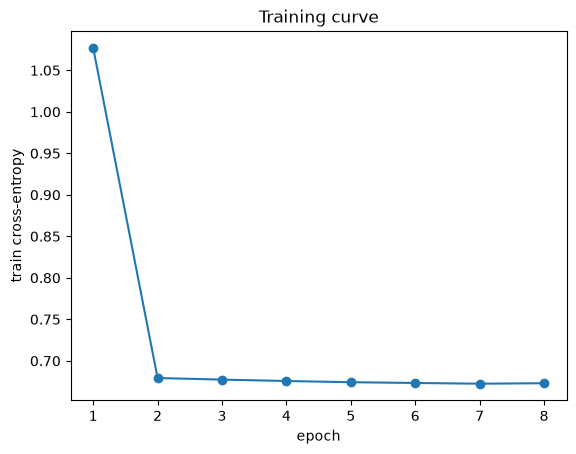

In [12]:
plt.plot(range(1, len(history) + 1), history, "o-")
plt.xlabel("epoch"); plt.ylabel("train cross-entropy"); plt.title("Training curve"); plt.show()

### 6.5 LSTM predictions

In [13]:
def lstm_topk(history, k=3):
    model.eval()
    with torch.no_grad():
        x = torch.tensor([[tok[e] for e in history]])
        logits = model(x)[0, -1]                   # logits at the LAST position
        logits[PAD] = -1e9                         # never predict padding
        top = torch.topk(logits, k).indices.tolist()
    return [itos[i] for i in top]

print(lstm_topk(["Received", "Triaged", "InfoRequested", "InfoReceived", "Quoted"]))

['NTU', 'Bound', 'Requoted']


---
## 7. Observations: accuracy@1 and accuracy@3

In [14]:
def accuracy_at_k(predict, cases, k):
    return np.mean([target in predict(hist, k) for hist, target in cases])

most_common = [e for e, _ in Counter(e for j in train_j for e in j[1:]).most_common(3)]
models = {
    "Most frequent event": lambda h, k: most_common[:k],
    "Markov order 1": m1.topk,
    "Markov order 2": m2.topk,
    "LSTM": lstm_topk,
}
hard = [(h, t) for h, t in test_cases if h[-1] in ("Quoted", "Requoted")]

rows = []
for name, f in models.items():
    rows.append({"model": name,
                 "acc@1 (all)":  accuracy_at_k(f, test_cases, 1),
                 "acc@3 (all)":  accuracy_at_k(f, test_cases, 3),
                 "acc@1 (after Quoted/Requoted)": accuracy_at_k(f, hard, 1)})
res = pd.DataFrame(rows).set_index("model").round(3)
res

,acc@1 (all),acc@3 (all),acc@1 (after Quoted/Requoted)
model,,,
Most frequent event,0.230,0.547,0.000
Markov order 1,0.663,0.983,0.544
Markov order 2,0.669,0.983,0.569
LSTM,0.651,0.983,0.563


### How to read this table
- **acc@3 (all)** is close to 1 for every sensible model, because from most states there are only 2 or 3 possible next events. **accuracy@k with k ≥ the branching factor is not informative.** Always check how many options there really are.
- The **"after Quoted/Requoted"** column is where the outcome is uncertain and the history effect lives (info loops, referral). This is where a model with memory should gain, if it gains anywhere.
- Next-event accuracy can't beat the **inherent randomness**: if P(Bound) = 0.6 for a journey, even a perfect model is wrong 40% of the time at acc@1.

### A sharper comparison: probability quality on the outcome step
Accuracy only checks the top guess. **Log-loss** checks whether the **probabilities** are right, and that's what a decisioning system consumes.

In [15]:
def outcome_probs_lstm(hist):
    model.eval()
    with torch.no_grad():
        p = torch.softmax(model(torch.tensor([[tok[e] for e in hist]]))[0, -1], -1)
    return p[tok["Bound"]].item()

def outcome_probs_markov1(hist):
    row = m1.counts[hist[-1]]
    return row["Bound"] / (row["Bound"] + row["NTU"])

def outcome_probs_markov2(hist):
    row = m2.counts.get((hist[-2], hist[-1])) or m1.counts[hist[-1]]
    return row["Bound"] / (row["Bound"] + row["NTU"])

bind_cases = [(h, t) for h, t in hard if t in ("Bound", "NTU")]
y = np.array([t == "Bound" for _, t in bind_cases], dtype=float)
eps = 1e-6
for name, f in [("Markov order 1", outcome_probs_markov1), ("Markov order 2", outcome_probs_markov2), ("LSTM", outcome_probs_lstm)]:
    p = np.clip([f(h) for h, _ in bind_cases], eps, 1 - eps)
    ll = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
    print(f"{name:15s} log-loss on Bound/NTU step = {ll:.4f}   (lower is better)")

Markov order 1  log-loss on Bound/NTU step = 0.6296   (lower is better)
Markov order 2  log-loss on Bound/NTU step = 0.6075   (lower is better)


LSTM            log-loss on Bound/NTU step = 0.6262   (lower is better)


### Result and conclusion (write yours after running)
Fill this in from **your** run. Don't just copy a conclusion: say what the table shows.

- Did the LSTM beat Markov order 1 on the hard positions? By how much?
- Did Markov order 2 capture most of that gain? (It sees "Referred → Quoted" but not "two info loops ago".)
- Was it worth it? An LSTM costs training infrastructure, monitoring and explainability. A count table is auditable by an underwriter.

**What a typical run shows:** the second-order Markov chain matches or slightly beats the LSTM on the hard positions, and the LSTM's log-loss edge over the first-order chain is tiny. The history effect is real, but it's small next to the inherent randomness of bind/NTU, so 7,000 parameters of memory buy almost nothing over a count table.

**The interview line:** "On a short lifecycle the Markov baseline got me essentially all the way. The LSTM couldn't show a meaningful gain even though I'd built a long-range effect into the simulator, because the effect was small relative to the noise. So I'd pick the model by its measured lift at the decision point against its operational cost, and here the count table wins."

---
## Exercise 2.1
1. Change `gen_journey` so P(bind) does **not** depend on info loops (delete `0.15 * path.count(...)`). Re-run. What happens to the LSTM's advantage? Why?
2. Re-run with a **random** split instead of the time split. Does anything change here? Why might it change on real data? (Hint: the synthetic data has no drift.)
3. Replace `nn.LSTM` with `nn.GRU`. What do you need to change in `forward`?
4. What is the shape of `logits` for a batch of 128 journeys whose longest input is 9 events?
5. Why do we set `logits[PAD] = -1e9` before `topk`?

<details><summary><b>Answers</b></summary>

1. The history effect is gone, so the process becomes (almost) first-order Markov. The LSTM has nothing extra to learn and its advantage disappears. **A model can only beat the baseline if the data has structure the baseline can't represent.**
2. Very little, because the simulator is stationary (no drift). Real data has drift (market cycles, new brokers, appetite changes), so a random split leaks the future and overstates accuracy.
3. Nothing in `forward`, since `out, _ = self.gru(...)` returns `(output, h_n)` just as the LSTM returns `(output, (h_n, c_n))` and we discard the second item. Only the constructor changes.
4. (128, 9, 11): batch × seq_len × vocab.
5. PAD is not a real event. Without the mask, the model could in principle rank it in the top-k.
</details>

## Viva Questions
**Q. How would you know whether a deep sequence model is worth it over a Markov chain?**
Compare them on a time-based split, on the positions that matter for the decision, using probability metrics (log-loss, calibration) and not just top-1 accuracy. Then weigh the lift against operational cost: explainability, monitoring and retraining. If the lift is small, ship the baseline.

**Q. Walk me through a PyTorch training step.**
Forward pass → loss → `zero_grad` → `backward` → `step`. At inference use `model.eval()` and `torch.no_grad()`. Handle variable-length sequences with padding and `ignore_index` (or `pack_padded_sequence`), and use `batch_first=True`.

## How to say it on Friday
> "This week I built a small comparison on a synthetic submission lifecycle: first- and second-order Markov against a PyTorch LSTM, with a time-based split. The useful lessons were that accuracy@3 was saturated for every model, so you have to evaluate at the decision point and on probability quality, and that a second-order Markov chain was as good as the LSTM."